# Class 1：从 Attention 到一个能训练的 Transformer

对象：会一点 Python，没有深度学习基础。请先预测每个实验的结果，再运行。
本 Notebook 可从仓库根目录或 class1 目录启动。首次安装见 README，选项目 `.venv` 内核。
本课没有外部模型、API 或 GPU 依赖。保留的输出来自一次实际执行；重新运行会刷新它们。

In [1]:
import sys
from pathlib import Path

start = Path.cwd().resolve()
candidates = [start, start / 'class1', start.parent / 'class1']
CLASS1 = next((p for p in candidates if (p / 'code/attention_demo.py').is_file()), None)
if CLASS1 is None:
    raise RuntimeError('请从仓库根目录或 class1 目录打开 Notebook')
sys.path.insert(0, str(CLASS1 / 'code'))
print('Python:', sys.version.split()[0])

Python: 3.13.5


## 1. 文字变数字：先认识列表和查表

一个数字列表称为向量，多个等长数字列表叠起来称为矩阵。
本课按空格分词，真实模型可能用子词等单位。ID 只是编号，embedding 则是一组会训练的数字。
第一个 Attention 演示直接使用人工 Q/K/V，不先训练 embedding。

In [2]:
text = '我 喜欢 喝 茶'
print('教学分词：', text.split())
from attention_demo import Q, K, V, TOKENS, attention, print_matrix
print('演示位置：', TOKENS)
print_matrix('Q', Q)
print_matrix('K', K)
print_matrix('V', V)

教学分词： ['我', '喜欢', '喝', '茶']
演示位置： ['我', '喜欢', '猫']
Q
  [  1.000,   0.000]
  [  0.000,   1.000]
  [  1.000,   1.000]
K
  [  1.000,   0.000]
  [  0.000,   1.000]
  [  1.000,   1.000]
V
  [  1.000,   0.000]
  [  0.000,   2.000]
  [  3.000,   1.000]


## 2. Attention：匹配 → softmax → 混合

手算第一行：`[1,0]` 与三个 key 点积、除以 √2，约为 `[0.707,0,0.707]`。
softmax 得到约 `[0.401,0.198,0.401]`，输出是 V 的加权混合，仍是向量。
行是 query，列是 key；每行权重之和为 1。

In [3]:
scores, weights, output = attention(Q, K, V)
print_matrix('匹配分数', scores)
print_matrix('Attention 权重', weights)
print_matrix('输出向量', output)
print('各行权重之和：', [round(sum(row), 6) for row in weights])

匹配分数
  [  0.707,   0.000,   0.707]
  [  0.000,   0.707,   0.707]
  [  0.707,   0.707,   1.414]
Attention 权重
  [  0.401,   0.198,   0.401]
  [  0.198,   0.401,   0.401]
  [  0.248,   0.248,   0.503]
输出向量
  [  1.604,   0.797]
  [  1.401,   1.203]
  [  1.759,   1.000]
各行权重之和： [1.0, 1.0, 1.0]


### 实验 A：只改 V（运行前先猜）

把最后一个 V 改成 `[30,10]`。Q/K 没变：权重会变吗？输出会变吗？

In [4]:
changed_v = [list(row) for row in V]
changed_v[2] = [30.0, 10.0]
_, changed_weights, changed_output = attention(Q, K, changed_v)
print('权重相同：', weights == changed_weights)
print_matrix('修改 V 后的输出', changed_output)

权重相同： True
修改 V 后的输出
  [ 12.434,   4.407]
  [ 12.231,   4.813]
  [ 15.353,   5.531]


### 因果遮罩：不能读到未来的位置

未来位置的分数设为负无穷，再计算 softmax。第一行只能看自己。
当前位置预测的是下一个 token，因此对角线允许读取。

In [5]:
causal_scores, causal_weights, causal_output = attention(Q, K, V, causal=True)
print_matrix('有遮罩的分数', causal_scores)
print_matrix('有遮罩的权重', causal_weights)
print_matrix('有遮罩的输出', causal_output)
_, _, causal_changed = attention(Q, K, changed_v, causal=True)
print('只改第三个 V，前两个输出不变：', causal_output[:2] == causal_changed[:2])

有遮罩的分数
  [  0.707,    -inf,    -inf]
  [  0.000,   0.707,    -inf]
  [  0.707,   0.707,   1.414]
有遮罩的权重
  [  1.000,   0.000,   0.000]
  [  0.330,   0.670,   0.000]
  [  0.248,   0.248,   0.503]
有遮罩的输出
  [  1.000,   0.000]
  [  0.330,   1.340]
  [  1.759,   1.000]
只改第三个 V，前两个输出不变： True


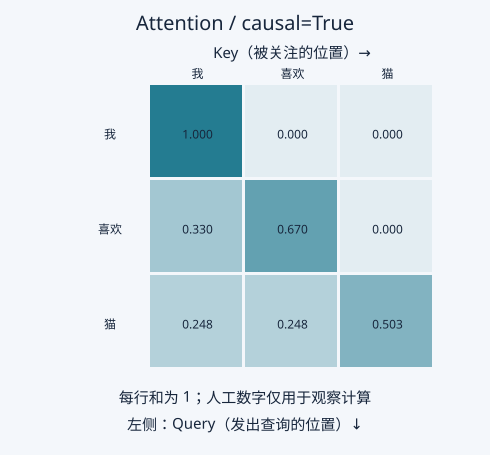

In [6]:
from IPython.display import SVG, display
from attention_demo import save_heatmap
heatmap_path = CLASS1 / 'outputs' / 'attention_causal.svg'
save_heatmap(causal_weights, heatmap_path, causal=True)
display(SVG(filename=str(heatmap_path)))

## 3. 训练一个真实的小型 Transformer

PyTorch 为我们计算梯度。模型：1 个 Block、2 头、D=32、Pre-LN。
有因果 self-attention、FFN、残差、LayerNorm、可学习的 token/position embedding。
数据只有八句人工语料；空格分词。没有验证集，观察的是训练集拟合。
没安装 PyTorch 时，先按 README 安装，然后重启内核并按顺序运行。

In [7]:
import torch
from tiny_transformer import (SENTENCES, VOCAB, TOKEN_TO_ID, BOS, EOS,
                              TinyTransformer, make_batch, decode,
                              train_model, generate, encode)
print('PyTorch:', torch.__version__)
print('人工语料：', SENTENCES)
print('词表：', TOKEN_TO_ID)
x, y = make_batch()
print('x[0]:', decode(x[0]))
print('y[0]:', decode(y[0]))
print('x/y 形状：', tuple(x.shape), tuple(y.shape))

PyTorch: 2.14.1
人工语料： ['我 喜欢 吃 苹果 。', '我 喜欢 吃 香蕉 。', '我 喜欢 喝 茶 。', '我 喜欢 喝 牛奶 。', '你 喜欢 吃 苹果 。', '你 喜欢 吃 香蕉 。', '你 喜欢 喝 茶 。', '你 喜欢 喝 牛奶 。']
词表： {'<bos>': 0, '<eos>': 1, '。': 2, '你': 3, '吃': 4, '喜欢': 5, '喝': 6, '我': 7, '牛奶': 8, '苹果': 9, '茶': 10, '香蕉': 11}
x[0]: <bos> 我 喜欢 吃 苹果 。
y[0]: 我 喜欢 吃 苹果 。 <eos>
x/y 形状： (8, 6) (8, 6)


### 先只做一次 forward：看形状，不更新参数

B=8，T=6，D=32，H=2；12 个词表 token。
输入 `[8,6]` → 向量 `[8,6,32]` → logits `[8,6,12]`。
注意权重是 `[8,2,6,6]`，最后两个维度是 query 位置和 key 位置。

In [8]:
torch.manual_seed(42)
initial_model = TinyTransformer()
with torch.no_grad():
    embedded = (initial_model.token_embedding(x)
                + initial_model.position_embedding(torch.arange(x.shape[1])))
    logits, head_weights = initial_model(x)
print('向量形状：', tuple(embedded.shape))
print('logits 形状：', tuple(logits.shape))
print('Attention 形状：', tuple(head_weights.shape))
print('第一句、第一头的权重：')
print(head_weights[0, 0].round(decimals=3))

向量形状： (8, 6, 32)
logits 形状： (8, 6, 12)
Attention 形状： (8, 2, 6, 6)
第一句、第一头的权重：
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4700, 0.5300, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3410, 0.2680, 0.3910, 0.0000, 0.0000, 0.0000],
        [0.2780, 0.3650, 0.1770, 0.1800, 0.0000, 0.0000],
        [0.1880, 0.2690, 0.2620, 0.1360, 0.1450, 0.0000],
        [0.2060, 0.2440, 0.1660, 0.1520, 0.0800, 0.1520]])


### 训练：loss → backward → 更新参数

每个位置预测右边的 token。交叉熵可理解为 `−log p(正确 token)`。
原始 logits 传给 cross_entropy；不要先 softmax。
`train_model` 会固定随机种子，在 CPU 上训练 200 步。

In [9]:
model, report = train_model(steps=200, seed=42)
print('参数量：', report['parameters'])
print(f"loss: {report['initial_loss']:.4f} → {report['final_loss']:.4f}")
print('训练前：', report['before_training'])
print('训练后：', report['after_training'])
print('本次训练耗时：', report['elapsed_seconds'], '秒')

step   1 | train loss 1.9257
step  25 | train loss 0.3536
step  50 | train loss 0.3482
step  75 | train loss 0.3477
step 100 | train loss 0.3475
step 125 | train loss 0.3473
step 150 | train loss 0.3472
step 175 | train loss 0.3471
step 200 | train loss 0.3471
参数量： 14060
loss: 2.6010 → 0.3471
训练前： 我 喜欢 牛奶 香蕉 你 茶 <eos>
训练后： 我 喜欢 喝 茶 。 <eos>
本次训练耗时： 0.155 秒


## 4. 逐步生成，再改 prompt

生成取最后一个位置的 logits，softmax 后贪心选最高概率 token。
选择结果追加到前文，循环到 `<eos>`；整个过程不更新参数。
概率非常接近的两个候选，不同版本训练后可能交换排序。

In [10]:
print('最终生成：', generate(model, prompt='我 喜欢', trace=True))

第 1 步，上下文：<bos> 我 喜欢
  候选： [{'token': '喝', 'probability': 0.5006}, {'token': '吃', 'probability': 0.499}, {'token': '。', 'probability': 0.0001}, {'token': '<eos>', 'probability': 0.0001}]
第 2 步，上下文：<bos> 我 喜欢 喝
  候选： [{'token': '茶', 'probability': 0.4997}, {'token': '牛奶', 'probability': 0.4995}, {'token': '<bos>', 'probability': 0.0001}, {'token': '喜欢', 'probability': 0.0001}]
第 3 步，上下文：<bos> 我 喜欢 喝 茶
  候选： [{'token': '。', 'probability': 0.9996}, {'token': '喜欢', 'probability': 0.0001}, {'token': '茶', 'probability': 0.0}, {'token': '<eos>', 'probability': 0.0}]
第 4 步，上下文：<bos> 我 喜欢 喝 茶 。
  候选： [{'token': '<eos>', 'probability': 0.9996}, {'token': '喜欢', 'probability': 0.0001}, {'token': '。', 'probability': 0.0001}, {'token': '我', 'probability': 0.0}]
最终生成： 我 喜欢 喝 茶 。 <eos>


In [11]:
prompt = '你 喜欢 喝'  # 实验 B：换为 '我 喜欢 吃'，先预测再运行
print('最终生成：', generate(model, prompt=prompt, trace=True))

第 1 步，上下文：<bos> 你 喜欢 喝
  候选： [{'token': '牛奶', 'probability': 0.4997}, {'token': '茶', 'probability': 0.4995}, {'token': '<bos>', 'probability': 0.0001}, {'token': '。', 'probability': 0.0001}]
第 2 步，上下文：<bos> 你 喜欢 喝 牛奶
  候选： [{'token': '。', 'probability': 0.9996}, {'token': '喜欢', 'probability': 0.0001}, {'token': '吃', 'probability': 0.0001}, {'token': '<eos>', 'probability': 0.0}]
第 3 步，上下文：<bos> 你 喜欢 喝 牛奶 。
  候选： [{'token': '<eos>', 'probability': 0.9996}, {'token': '喜欢', 'probability': 0.0001}, {'token': '。', 'probability': 0.0001}, {'token': '我', 'probability': 0.0}]
最终生成： 你 喜欢 喝 牛奶 。 <eos>


### 检查一个关键性质：改变未来 token，不影响更早的预测

保持前四个输入位置不变，只改后面位置，比较前四个位置的 logits。

In [12]:
model.eval()
altered = x.clone()
altered[:, 4:] = TOKEN_TO_ID['茶']
with torch.no_grad():
    original_logits, _ = model(x)
    changed_logits, _ = model(altered)
difference = (original_logits[:, :4] - changed_logits[:, :4]).abs().max().item()
print('前四个位置 logits 最大差异：', difference)
torch.testing.assert_close(original_logits[:, :4], changed_logits[:, :4])

前四个位置 logits 最大差异： 0.0


## 离开课堂前，自己说一遍

1. Attention 输出是什么？Q/K/V 分别影响什么？
2. 为什么第一行因果权重是 `[1,0,0]`？
3. 训练与生成的区别是什么？
4. 画出 token 到下一 token 的流程，标出 logits 的形状。

结果边界：loss 下降显示对八句人工语料拟合更好；没有验证集，不能判断泛化。
多种合法后续使 loss 不必为 0。参考 [学生讲义](student_handout.md) 和 [原论文](https://arxiv.org/abs/1706.03762)。